In [1]:
# Cell 1: Setup & Dummy Dirty Dataset
import re
import pandas as pd
import numpy as np

raw_data = {
    "order_id": [101, 102, 103, 103, 104, 105, 106, 107],
    "customer_name": [
        "  andi   pratama ",
        "BUDI SANTOSO",
        "siti aminah  ",
        "siti aminah  ",
        None,
        "  kenji's store  ",
        "raka   wijaya",
        "  DEWI LESTARI  ",
    ],
    "notes": [
        "  first order. needs fast delivery.  ",
        "PACKAGE ARRIVED LATE. please check!",
        None,
        None,
        "   customer asked for invoice. ",
        "  don't forget to pack securely. ",
        "urgent item",
        "  all good! ",
    ],
    "amount_idr": [150000.0, 250000.0, np.nan, np.nan, 300000.0, 450000.0, np.nan, 200000.0],
    "quantity": [2, 1, 3, 3, None, 4, 2, 1],
}

df_raw = pd.DataFrame(raw_data)
print("Ukuran awal (baris, kolom):", df_raw.shape)
display(df_raw)

Ukuran awal (baris, kolom): (8, 5)


,order_id,customer_name,notes,amount_idr,quantity
0,101,andi pratama,first order. needs fast delivery.,150000.0,2.0
1,102,BUDI SANTOSO,PACKAGE ARRIVED LATE. please check!,250000.0,1.0
2,103,siti aminah,None,NaN,3.0
3,103,siti aminah,None,NaN,3.0
4,104,None,customer asked for invoice.,300000.0,NaN
5,105,kenji's store,don't forget to pack securely.,450000.0,4.0
6,106,raka wijaya,urgent item,NaN,2.0
7,107,DEWI LESTARI,all good!,200000.0,1.0


In [3]:
# Cell 2: Whitespace & MS Word-Style Text Case Helpers

def trim_text_series(s: pd.Series, collapse_inner_spaces: bool = True) -> pd.Series:
    """Membersihkan spasi di awal/akhir dan merapikan spasi berlebih di dalam teks."""
    def _clean_str(val):
        if pd.isna(val):
            return val
        text = str(val).strip()
        if collapse_inner_spaces:
            text = re.sub(r"\s+", " ", text)
        return text

    return s.apply(_clean_str)


def _to_sentence_case(text: str) -> str:
    """Mengkapitalisasi huruf pertama setiap kalimat (setelah awal teks atau tanda ., !, ?)."""
    lowered = text.lower()
    # Kapitalisasi karakter pertama non-spasi
    lowered = re.sub(r"^\s*([a-z])", lambda m: m.group(0).upper(), lowered)
    # Kapitalisasi huruf pertama setelah tanda akhir kalimat + spasi
    lowered = re.sub(r"([.!?]\s+)([a-z])", lambda m: m.group(1) + m.group(2).upper(), lowered)
    return lowered


def _to_capitalize_each_word(text: str) -> str:
    """Kapitalisasi awal kata tanpa merusak kata ber-apostrof seperti don't -> Don't."""
    def _cap_token(token: str) -> str:
        if not token:
            return token
        # Jika ada apostrof di tengah kata (misal kenji's atau don't), kapitalisasi bagian depan saja
        if "'" in token:
            parts = token.split("'")
            parts[0] = parts[0][:1].upper() + parts[0][1:].lower() if parts[0] else ""
            for i in range(1, len(parts)):
                parts[i] = parts[i].lower()
            return "'".join(parts)
        return token[:1].upper() + token[1:].lower()

    return re.sub(r"\S+", lambda m: _cap_token(m.group(0)), text)


def apply_text_case(s: pd.Series, case_mode: str | None) -> pd.Series:
    """Menerapkan mode huruf: None, sentence, lower, upper, capitalize_each_word, toggle."""
    if not case_mode or case_mode == "none":
        return s

    def _transform(val):
        if pd.isna(val):
            return val
        text = str(val)
        if case_mode == "sentence":
            return _to_sentence_case(text)
        elif case_mode == "lower":
            return text.lower()
        elif case_mode == "upper":
            return text.upper()
        elif case_mode == "capitalize_each_word":
            return _to_capitalize_each_word(text)
        elif case_mode == "toggle":
            return text.swapcase()
        else:
            raise ValueError(f"Unsupported case_mode: {case_mode}")

    return s.apply(_transform)

print("Helper functions loaded successfully.")

Helper functions loaded successfully.


In [4]:
# Cell 3: Core Data Cleaning Pipeline

DEFAULT_CONFIG = {
    "remove_duplicates": True,
    "missing_strategy": "median",   # options: "none", "median", "mean", "drop"
    "trim_whitespace": True,
    "case_mode": "none",            # options: "none", "sentence", "lower", "upper", "capitalize_each_word", "toggle"
    "case_columns": None,           # None = semua kolom bertipe object/string; atau list nama kolom tertentu
}


def clean_dataset(df: pd.DataFrame, config: dict | None = None) -> tuple[pd.DataFrame, dict]:
    cfg = {**DEFAULT_CONFIG, **(config or {})}
    work_df = df.copy()

    initial_rows, initial_cols = work_df.shape
    initial_missing = int(work_df.isna().sum().sum())
    initial_duplicates = int(work_df.duplicated().sum())

    # 1. Trim whitespace (jika aktif)
    if cfg["trim_whitespace"]:
        text_cols = work_df.select_dtypes(include=["object", "string"]).columns
        for col in text_cols:
            work_df[col] = trim_text_series(work_df[col], collapse_inner_spaces=True)

    # 2. Change text case (Advanced Settings, jika dipilih)
    case_mode = cfg["case_mode"]
    if case_mode and case_mode != "none":
        if cfg["case_columns"]:
            target_cols = [c for c in cfg["case_columns"] if c in work_df.columns]
        else:
            target_cols = list(work_df.select_dtypes(include=["object", "string"]).columns)

        for col in target_cols:
            work_df[col] = apply_text_case(work_df[col], case_mode)

    # 3. Remove exact duplicates
    removed_duplicates = 0
    if cfg["remove_duplicates"]:
        before_dup = len(work_df)
        work_df = work_df.drop_duplicates().reset_index(drop=True)
        removed_duplicates = before_dup - len(work_df)

    # 4. Handle missing values
    strategy = cfg["missing_strategy"]
    rows_dropped_missing = 0
    numeric_filled_cells = 0

    if strategy == "drop":
        before_drop = len(work_df)
        work_df = work_df.dropna().reset_index(drop=True)
        rows_dropped_missing = before_drop - len(work_df)
    elif strategy in ("median", "mean"):
        num_cols = work_df.select_dtypes(include=[np.number]).columns
        for col in num_cols:
            na_count = int(work_df[col].isna().sum())
            if na_count > 0:
                fill_val = work_df[col].median() if strategy == "median" else work_df[col].mean()
                if pd.notna(fill_val):
                    work_df[col] = work_df[col].fillna(fill_val)
                    numeric_filled_cells += na_count

    final_rows, final_cols = work_df.shape
    final_missing = int(work_df.isna().sum().sum())

    summary = {
        "initial_rows": initial_rows,
        "final_rows": final_rows,
        "initial_cols": initial_cols,
        "final_cols": final_cols,
        "initial_duplicates": initial_duplicates,
        "removed_duplicates": removed_duplicates,
        "initial_missing": initial_missing,
        "final_missing": final_missing,
        "numeric_filled_cells": numeric_filled_cells,
        "rows_dropped_missing": rows_dropped_missing,
        "applied_config": cfg,
    }

    return work_df, summary

print("clean_dataset() ready.")

clean_dataset() ready.


In [5]:
# Cell 4: Test Scenarios

# Skenario A: Recommended default (trim + dedup + median missing numeric, case = none)
df_clean_a, sum_a = clean_dataset(df_raw, {
    "remove_duplicates": True,
    "missing_strategy": "median",
    "trim_whitespace": True,
    "case_mode": "none",
})
print("=== SKENARIO A (Default) ===")
print("Summary:", sum_a)
display(df_clean_a)

# Skenario B: Uji 5 mode case pada kolom customer_name & notes
for mode in ["sentence", "lower", "upper", "capitalize_each_word", "toggle"]:
    df_test, _ = clean_dataset(df_raw, {
        "remove_duplicates": True,
        "missing_strategy": "median",
        "trim_whitespace": True,
        "case_mode": mode,
        "case_columns": ["customer_name", "notes"],
    })
    print(f"\n--- Mode: {mode} ---")
    display(df_test[["customer_name", "notes"]].head(4))

=== SKENARIO A (Default) ===
Summary: {'initial_rows': 8, 'final_rows': 7, 'initial_cols': 5, 'final_cols': 5, 'initial_duplicates': 1, 'removed_duplicates': 1, 'initial_missing': 7, 'final_missing': 2, 'numeric_filled_cells': 3, 'rows_dropped_missing': 0, 'applied_config': {'remove_duplicates': True, 'missing_strategy': 'median', 'trim_whitespace': True, 'case_mode': 'none', 'case_columns': None}}


,order_id,customer_name,notes,amount_idr,quantity
0,101,andi pratama,first order. needs fast delivery.,150000.0,2.0
1,102,BUDI SANTOSO,PACKAGE ARRIVED LATE. please check!,250000.0,1.0
2,103,siti aminah,None,250000.0,3.0
3,104,None,customer asked for invoice.,300000.0,2.0
4,105,kenji's store,don't forget to pack securely.,450000.0,4.0
5,106,raka wijaya,urgent item,250000.0,2.0
6,107,DEWI LESTARI,all good!,200000.0,1.0



--- Mode: sentence ---


,customer_name,notes
0,Andi pratama,First order. Needs fast delivery.
1,Budi santoso,Package arrived late. Please check!
2,Siti aminah,None
3,None,Customer asked for invoice.



--- Mode: lower ---


,customer_name,notes
0,andi pratama,first order. needs fast delivery.
1,budi santoso,package arrived late. please check!
2,siti aminah,None
3,None,customer asked for invoice.


... (2 outputs left out)


--- Mode: capitalize_each_word ---


,customer_name,notes
0,Andi Pratama,First Order. Needs Fast Delivery.
1,Budi Santoso,Package Arrived Late. Please Check!
2,Siti Aminah,None
3,None,Customer Asked For Invoice.



--- Mode: toggle ---


,customer_name,notes
0,ANDI PRATAMA,FIRST ORDER. NEEDS FAST DELIVERY.
1,budi santoso,package arrived late. PLEASE CHECK!
2,SITI AMINAH,None
3,None,CUSTOMER ASKED FOR INVOICE.


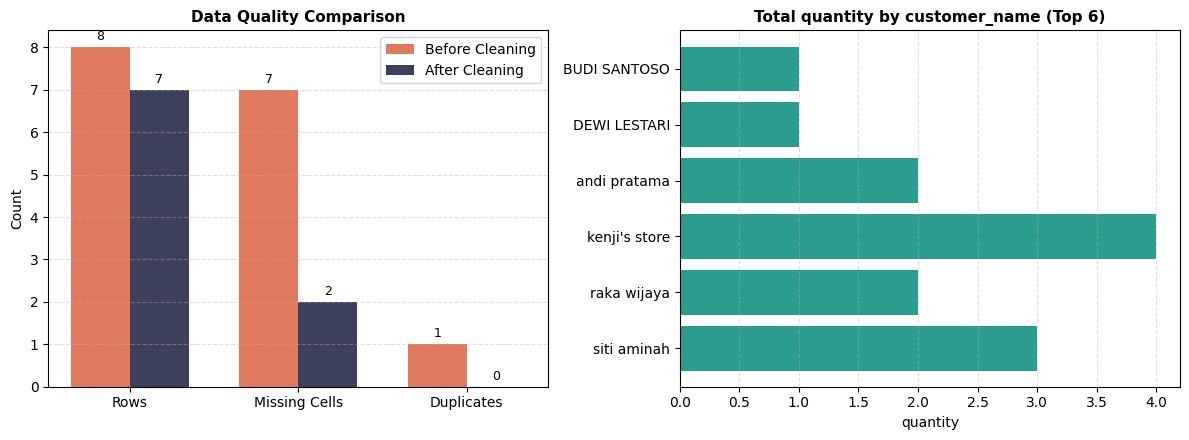

Chart saved to: cleaning_summary_chart.png


In [6]:
# Cell 5: Summary Charts (Before vs After Cleaning + Cleaned Data Overview)
import matplotlib.pyplot as plt
import numpy as np

def generate_summary_charts(df_before: pd.DataFrame, df_after: pd.DataFrame, summary: dict, output_path: str = "cleaning_summary_chart.png"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    fig.patch.set_facecolor("white")

    # Chart 1: Before vs After Cleaning Metrics
    metrics = ["Rows", "Missing Cells", "Duplicates"]
    before_vals = [
        summary["initial_rows"],
        summary["initial_missing"],
        summary["initial_duplicates"],
    ]
    after_vals = [
        summary["final_rows"],
        summary["final_missing"],
        int(df_after.duplicated().sum()),
    ]

    x = np.arange(len(metrics))
    width = 0.35

    bars1 = axes[0].bar(x - width / 2, before_vals, width, label="Before Cleaning", color="#E07A5F")
    bars2 = axes[0].bar(x + width / 2, after_vals, width, label="After Cleaning", color="#3D405B")

    axes[0].set_title("Data Quality Comparison", fontsize=11, fontweight="bold")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(metrics)
    axes[0].set_ylabel("Count")
    axes[0].legend()
    axes[0].grid(axis="y", linestyle="--", alpha=0.4)

    for bar in bars1:
        h = bar.get_height()
        axes[0].annotate(f"{int(h)}", xy=(bar.get_x() + bar.get_width() / 2, h),
                         xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)
    for bar in bars2:
        h = bar.get_height()
        axes[0].annotate(f"{int(h)}", xy=(bar.get_x() + bar.get_width() / 2, h),
                         xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)

    # Chart 2: Overview of Cleaned Dataset (Numeric column sum/mean or column non-null counts)
    num_cols = df_after.select_dtypes(include=[np.number]).columns.tolist()
    # Hindari kolom ID jika ada
    plot_num_cols = [c for c in num_cols if "id" not in c.lower()]

    if len(plot_num_cols) > 0:
        target_col = plot_num_cols[0]
        # Jika ada kolom kategori/teks, kelompokkan; jika tidak, tampilkan per baris index
        cat_cols = df_after.select_dtypes(include=["object", "string"]).columns.tolist()
        if len(cat_cols) > 0:
            grouped = df_after.groupby(cat_cols[0], dropna=False)[target_col].sum().head(6)
            axes[1].barh(grouped.index.astype(str), grouped.values, color="#2A9D8F")
            axes[1].invert_yaxis()
            axes[1].set_title(f"Total {target_col} by {cat_cols[0]} (Top 6)", fontsize=11, fontweight="bold")
            axes[1].set_xlabel(target_col)
        else:
            axes[1].plot(df_after.index, df_after[target_col], marker="o", color="#2A9D8F")
            axes[1].set_title(f"{target_col} Across Cleaned Rows", fontsize=11, fontweight="bold")
            axes[1].set_xlabel("Row Index")
            axes[1].set_ylabel(target_col)
        axes[1].grid(axis="x", linestyle="--", alpha=0.4)
    else:
        non_null = df_after.notna().sum()
        axes[1].barh(non_null.index.astype(str), non_null.values, color="#2A9D8F")
        axes[1].invert_yaxis()
        axes[1].set_title("Non-Null Values per Column", fontsize=11, fontweight="bold")
        axes[1].set_xlabel("Count")

    plt.tight_layout()
    plt.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    return output_path


chart_file = generate_summary_charts(df_raw, df_clean_a, sum_a)
print("Chart saved to:", chart_file)

In [7]:
# Cell 6: Install fpdf2 & Generate PDF Summary Report
!pip -q install fpdf2

from fpdf import FPDF


def _safe_pdf_text(text: str) -> str:
    """Memastikan teks aman untuk font standar Latin-1 di FPDF agar tidak memicu UnicodeEncodeError."""
    return str(text).encode("latin-1", errors="replace").decode("latin-1")


def build_summary_pdf(summary: dict, chart_image_path: str | None = None, output_pdf_path: str = "data_cleaning_summary.pdf") -> str:
    pdf = FPDF()
    pdf.set_auto_page_break(auto=True, margin=15)
    pdf.add_page()

    # Header
    pdf.set_font("Helvetica", "B", 16)
    pdf.cell(0, 10, _safe_pdf_text("Data Cleaning Summary Report"), ln=True)

    pdf.set_font("Helvetica", "", 10)
    pdf.set_text_color(100, 100, 100)
    pdf.cell(0, 6, _safe_pdf_text("Generated automatically from cleaned dataset"), ln=True)
    pdf.set_text_color(0, 0, 0)
    pdf.ln(4)

    # Section 1: Dataset Overview & Cleaning Metrics
    pdf.set_font("Helvetica", "B", 12)
    pdf.cell(0, 8, _safe_pdf_text("1. Dataset & Cleaning Metrics"), ln=True)
    pdf.set_font("Helvetica", "", 10)

    lines = [
        f"Rows: {summary['initial_rows']} -> {summary['final_rows']}",
        f"Columns: {summary['initial_cols']} -> {summary['final_cols']}",
        f"Duplicates Removed: {summary['removed_duplicates']} (Initial duplicates: {summary['initial_duplicates']})",
        f"Missing Cells: {summary['initial_missing']} -> {summary['final_missing']}",
        f"Numeric Missing Cells Filled: {summary['numeric_filled_cells']} | Rows Dropped (Missing): {summary['rows_dropped_missing']}",
    ]
    for line in lines:
        pdf.cell(0, 6.5, _safe_pdf_text(f"- {line}"), ln=True)

    pdf.ln(3)

    # Section 2: Applied Configuration
    cfg = summary.get("applied_config", {})
    pdf.set_font("Helvetica", "B", 12)
    pdf.cell(0, 8, _safe_pdf_text("2. Applied Cleaning Options"), ln=True)
    pdf.set_font("Helvetica", "", 10)

    cfg_lines = [
        f"Remove Duplicates: {cfg.get('remove_duplicates')}",
        f"Missing Value Strategy: {cfg.get('missing_strategy')}",
        f"Trim Whitespace: {cfg.get('trim_whitespace')}",
        f"Text Case Mode: {cfg.get('case_mode')}",
    ]
    for c_line in cfg_lines:
        pdf.cell(0, 6.5, _safe_pdf_text(f"- {c_line}"), ln=True)

    pdf.ln(4)

    # Section 3: Visual Summary Chart
    if chart_image_path:
        pdf.set_font("Helvetica", "B", 12)
        pdf.cell(0, 8, _safe_pdf_text("3. Visual Summary"), ln=True)
        pdf.image(chart_image_path, w=180)

    pdf.output(output_pdf_path)
    return output_pdf_path


pdf_file = build_summary_pdf(sum_a, chart_image_path=chart_file)
print("PDF generated at:", pdf_file)

PDF generated at: data_cleaning_summary.pdf


/tmp/ipykernel_587/927910296.py:19: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 10, _safe_pdf_text("Data Cleaning Summary Report"), ln=True)
/tmp/ipykernel_587/927910296.py:23: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 6, _safe_pdf_text("Generated automatically from cleaned dataset"), ln=True)
/tmp/ipykernel_587/927910296.py:29: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 8, _safe_pdf_text("1. Dataset & Cleaning Metrics"), ln=True)
/tmp/ipykernel_587/927910296.py:40: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 6.5, _safe_pdf_text(f"- {line}"), ln=True)
/tmp/ipykernel_587/927910296.py:47: DeprecationWarn